In [1]:
%pip -q install sentencepiece sacrebleu transformers sacremoses pandas numpy scikit-learn matplotlib

In [2]:
import csv
import json
import os
import random
import re
import shutil
import tempfile
import time
import unicodedata
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import sentencepiece as spm
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: Training two LSTMs without a GPU can take considerably longer.')
print('PyTorch:', torch.__version__)

Device: cuda
GPU: Tesla T4
PyTorch: 2.14.1+cu130


In [3]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = Path('/content/drive/MyDrive/NMT_Three_Model_Comparison')
    print('Google Drive connected. Checkpoints will survive Colab disconnections.')
except ImportError:
    SAVE_DIR = Path.cwd() / 'NMT_Three_Model_Comparison'
    print('Not running in Colab: using a local results directory instead.')

SAVE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Checkpoint directory:', SAVE_DIR.resolve())

Mounted at /content/drive
Google Drive connected. Checkpoints will survive Colab disconnections.
Checkpoint directory: /content/drive/MyDrive/NMT_Three_Model_Comparison


In [4]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip'
ZIP_PATH = Path('fra-eng.zip')
EXTRACT_DIR = Path('data_raw')

if not ZIP_PATH.exists():
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
EXTRACT_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)

text_files = list(EXTRACT_DIR.rglob('fra.txt'))
assert text_files, 'Could not find fra.txt in the downloaded dataset.'

pairs = pd.read_csv(
    text_files[0], sep='\t', header=None, usecols=[0, 1],
    names=['en', 'fr'], quoting=csv.QUOTE_NONE, encoding='utf-8'
)
raw_count = len(pairs)
pairs = pairs.dropna(subset=['en', 'fr']).copy()
pairs['en'] = pairs['en'].str.strip()
pairs['fr'] = pairs['fr'].str.strip()
pairs['en_words'] = pairs['en'].str.split().str.len()
pairs = pairs[(pairs['en'] != '') & (pairs['fr'] != '')]
pairs = pairs.drop_duplicates(subset=['en', 'fr'])
pairs = pairs[pairs['en_words'] <= 15].reset_index(drop=True)

print('Raw sentence pairs:', raw_count)
print('Cleaned sentence pairs:', len(pairs))
display(pairs[['en', 'fr']].head())

Raw sentence pairs: 167130
Cleaned sentence pairs: 166340


,en,fr
0,Go.,Va !
1,Hi.,Salut !
2,Run!,Cours !
3,Run!,Courez !
4,Who?,Qui ?


In [5]:
def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text))
    text = text.casefold()
    return re.sub(r'\s+', ' ', text).strip()

def loose_normalize(text):
    text = normalize_text(text)
    text = re.sub(r'[\W_]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

pairs['en_key'] = pairs['en'].apply(normalize_text)
pairs['fr_key'] = pairs['fr'].apply(normalize_text)
pairs['en_loose'] = pairs['en'].apply(loose_normalize)
pairs['fr_loose'] = pairs['fr'].apply(loose_normalize)

parent = list(range(len(pairs)))
size = [1] * len(pairs)

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(a, b):
    root_a, root_b = find(a), find(b)
    if root_a == root_b:
        return
    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a
    parent[root_b] = root_a
    size[root_a] += size[root_b]

seen = {}
for i, (english, french) in enumerate(zip(pairs['en_loose'], pairs['fr_loose'])):
    for key in [('en', english), ('fr', french)]:
        if key in seen:
            union(i, seen[key])
        else:
            seen[key] = i

pairs['group_id'] = [find(i) for i in range(len(pairs))]

from sklearn.model_selection import GroupShuffleSplit
first_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, remaining_idx = next(first_split.split(pairs, groups=pairs['group_id']))
train_pairs = pairs.iloc[train_idx].reset_index(drop=True)
remaining_pairs = pairs.iloc[remaining_idx].reset_index(drop=True)

second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(second_split.split(
    remaining_pairs, groups=remaining_pairs['group_id']))
val_pairs = remaining_pairs.iloc[val_idx].reset_index(drop=True)
test_pairs = remaining_pairs.iloc[test_idx].reset_index(drop=True)

for left, right in [(train_pairs, val_pairs), (train_pairs, test_pairs),
                    (val_pairs, test_pairs)]:
    for column in ['en_key', 'fr_key', 'en_loose', 'fr_loose', 'group_id']:
        assert not (set(left[column]) & set(right[column])), (
            f'Data leakage found for {column}'
        )

print('Training pairs:', len(train_pairs))
print('Validation pairs:', len(val_pairs))
print('Test pairs:', len(test_pairs))
print('Leakage checks: PASSED')

Training pairs: 133017
Validation pairs: 16616
Test pairs: 16707
Leakage checks: PASSED


In [6]:
TEST_SIZE = 2000
MONITOR_SIZE = 1000

# Preserve the original Notebook 03 monitoring sample selection procedure.
legacy_val_500 = val_pairs.drop_duplicates(subset='en_key').sample(
    n=min(500, val_pairs['en_key'].nunique()), random_state=SEED
).reset_index(drop=True)
monitor_pool = val_pairs[~val_pairs['group_id'].isin(legacy_val_500['group_id'])]
monitor_df = monitor_pool.drop_duplicates(subset='en_key').sample(
    n=MONITOR_SIZE, random_state=43
).reset_index(drop=True)

test_df = test_pairs.drop_duplicates(subset='en_key').sample(
    n=TEST_SIZE, random_state=SEED
).reset_index(drop=True)

assert len(test_df) == TEST_SIZE
assert not set(train_pairs['group_id']) & set(monitor_df['group_id'])
assert not set(train_pairs['group_id']) & set(test_df['group_id'])
assert not set(monitor_df['group_id']) & set(test_df['group_id'])
assert test_df['en_key'].is_unique

print('Monitor sentences:', len(monitor_df))
print('Final held-out test sentences:', len(test_df))
print('No train/monitor/test group overlap.')
display(test_df[['en', 'fr']].head())

Monitor sentences: 1000
Final held-out test sentences: 2000
No train/monitor/test group overlap.


,en,fr
0,Who doesn't think so?,Qui ne pense pas de même ?
1,Tom didn't even know who that was.,Tom ne savait même pas qui c'était.
2,Tom put the screws in a small plastic bag.,Tom a mis les vis dans un petit sac en plastique.
3,"When the last customer leaves, we close the do...","Lorsque le dernier client s'en va, nous fermon..."
4,He works very hard.,Il travaille très dur.


In [7]:
TRAIN_LIMIT = 50000
EPOCHS = 5
PATIENCE = 2
BATCH_SIZE = 64
MAX_LEN = 48
VOCAB_SIZE = 6000
EMBED_DIM = 256
HIDDEN_DIM = 256
LEARNING_RATE = 0.001

train_df = train_pairs.sample(
    n=min(TRAIN_LIMIT, len(train_pairs)), random_state=SEED
).reset_index(drop=True)

CONFIG = {
    'seed': SEED, 'training_examples': len(train_df),
    'monitor_examples': len(monitor_df), 'test_examples': len(test_df),
    'epochs': EPOCHS, 'patience': PATIENCE, 'batch_size': BATCH_SIZE,
    'max_len': MAX_LEN, 'vocab_size': VOCAB_SIZE,
    'embed_dim': EMBED_DIM, 'hidden_dim': HIDDEN_DIM,
    'learning_rate': LEARNING_RATE,
}
print('Training examples per LSTM:', len(train_df))
print('Run configuration:', CONFIG)

Training examples per LSTM: 50000
Run configuration: {'seed': 42, 'training_examples': 50000, 'monitor_examples': 1000, 'test_examples': 2000, 'epochs': 5, 'patience': 2, 'batch_size': 64, 'max_len': 48, 'vocab_size': 6000, 'embed_dim': 256, 'hidden_dim': 256, 'learning_rate': 0.001}


In [8]:
with tempfile.TemporaryDirectory() as temp_folder:
    tmp = Path(temp_folder)
    en_path, fr_path = tmp / 'train.en', tmp / 'train.fr'
    en_path.write_text('\n'.join(train_df['en'].tolist()), encoding='utf-8')
    fr_path.write_text('\n'.join(train_df['fr'].tolist()), encoding='utf-8')
    for lang, path in [('en', en_path), ('fr', fr_path)]:
        spm.SentencePieceTrainer.train(
            input=str(path), model_prefix=str(tmp / lang),
            vocab_size=VOCAB_SIZE, model_type='bpe',
            character_coverage=1.0, hard_vocab_limit=False,
            pad_id=0, unk_id=1, bos_id=2, eos_id=3,
            num_threads=1,
        )
    en_sp = spm.SentencePieceProcessor(model_file=str(tmp / 'en.model'))
    fr_sp = spm.SentencePieceProcessor(model_file=str(tmp / 'fr.model'))

PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
assert en_sp.pad_id() == fr_sp.pad_id() == PAD_ID
assert en_sp.eos_id() == fr_sp.eos_id() == EOS_ID

(SAVE_DIR / 'english_sentencepiece.model').write_bytes(en_sp.serialized_model_proto())
(SAVE_DIR / 'french_sentencepiece.model').write_bytes(fr_sp.serialized_model_proto())

print('English vocabulary:', en_sp.vocab_size())
print('French vocabulary:', fr_sp.vocab_size())
print('Tokens:', en_sp.encode('I love learning French.', out_type=str))
print('Tokenizers backed up to Google Drive.')

English vocabulary: 6000
French vocabulary: 6000
Tokens: ['▁I', '▁love', '▁learning', '▁French', '.']
Tokenizers backed up to Google Drive.


In [9]:
def encode_english(text):
    return en_sp.encode(str(text), out_type=int)[:MAX_LEN - 1] + [EOS_ID]

def encode_french(text):
    return [BOS_ID] + fr_sp.encode(str(text), out_type=int)[:MAX_LEN - 2] + [EOS_ID]

class TranslationDataset(Dataset):
    def __init__(self, frame):
        self.sources = [encode_english(x) for x in frame['en']]
        self.targets = [encode_french(x) for x in frame['fr']]

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, idx):
        return (torch.tensor(self.sources[idx], dtype=torch.long),
                torch.tensor(self.targets[idx], dtype=torch.long))

def collate_translation(batch):
    sources, targets = zip(*batch)
    return (pad_sequence(sources, batch_first=True, padding_value=PAD_ID),
            pad_sequence(targets, batch_first=True, padding_value=PAD_ID))

train_dataset = TranslationDataset(train_df)
monitor_dataset = TranslationDataset(monitor_df)

def make_train_loader():
    # New, identically seeded shuffle generator for each model.
    return DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        collate_fn=collate_translation, num_workers=0,
        generator=torch.Generator().manual_seed(SEED)
    )

monitor_loader = DataLoader(
    monitor_dataset, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_translation, num_workers=0
)

src_batch, tgt_batch = next(iter(make_train_loader()))
print('Example batch shapes:', tuple(src_batch.shape), tuple(tgt_batch.shape))

Example batch shapes: (64, 20) (64, 26)


In [10]:
class Seq2SeqLSTM(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, embed_dim=256, hidden_dim=256,
                 use_attention=False):
        super().__init__()
        assert hidden_dim % 2 == 0
        self.use_attention = use_attention
        self.src_embedding = nn.Embedding(src_vocab, embed_dim, padding_idx=PAD_ID)
        self.encoder = nn.LSTM(
            embed_dim, hidden_dim // 2, batch_first=True, bidirectional=True
        )
        self.init_h = nn.Linear(hidden_dim, hidden_dim)
        self.init_c = nn.Linear(hidden_dim, hidden_dim)
        self.tgt_embedding = nn.Embedding(tgt_vocab, embed_dim, padding_idx=PAD_ID)
        self.decoder = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        if use_attention:
            assert hidden_dim % 4 == 0
            self.attention = nn.MultiheadAttention(
                embed_dim=hidden_dim, num_heads=4, batch_first=True
            )
        self.output = nn.Linear(hidden_dim * (2 if use_attention else 1), tgt_vocab)

    def encode(self, src):
        source_is_pad = src.eq(PAD_ID)
        lengths = src.ne(PAD_ID).sum(dim=1).cpu()
        embedded = self.src_embedding(src)
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        packed_outputs, (hidden, cell) = self.encoder(packed)
        encoder_outputs, _ = pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        initial_hidden = torch.tanh(self.init_h(
            torch.cat([hidden[-2], hidden[-1]], dim=-1)
        )).unsqueeze(0)
        initial_cell = torch.tanh(self.init_c(
            torch.cat([cell[-2], cell[-1]], dim=-1)
        )).unsqueeze(0)
        return encoder_outputs, (initial_hidden, initial_cell), source_is_pad

    def decode(self, target_inputs, states, encoder_outputs, source_is_pad):
        target_embeddings = self.tgt_embedding(target_inputs)
        decoder_outputs, new_states = self.decoder(target_embeddings, states)
        if self.use_attention:
            context, _ = self.attention(
                query=decoder_outputs, key=encoder_outputs, value=encoder_outputs,
                key_padding_mask=source_is_pad, need_weights=False
            )
            output_features = torch.cat([decoder_outputs, context], dim=-1)
        else:
            output_features = decoder_outputs
        logits = self.output(output_features)
        return logits, new_states

    def forward(self, src, target_inputs):
        encoder_outputs, states, source_is_pad = self.encode(src)
        logits, _ = self.decode(target_inputs, states, encoder_outputs, source_is_pad)
        return logits


def make_lstm(use_attention):
    torch.manual_seed(SEED)  # Same seed for shared weights in both variants.
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
    return Seq2SeqLSTM(
        src_vocab=en_sp.vocab_size(), tgt_vocab=fr_sp.vocab_size(),
        embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM,
        use_attention=use_attention
    ).to(DEVICE)

for attention in [False, True]:
    preview_model = make_lstm(attention)
    with torch.no_grad():
        logits = preview_model(
            src_batch[:2].to(DEVICE), tgt_batch[:2, :-1].to(DEVICE)
        )
    assert logits.shape == (2, tgt_batch.size(1) - 1, fr_sp.vocab_size())
    print(('With' if attention else 'Without') + ' attention:',
          f'{sum(p.numel() for p in preview_model.parameters()):,} parameters',
          '| forward check passed')
    del preview_model

Without attention: 5,667,184 parameters | forward check passed
With attention: 7,466,352 parameters | forward check passed


In [11]:
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD_ID)

@torch.no_grad()
def monitoring_loss(model, loader):
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    for source, target in loader:
        source, target = source.to(DEVICE), target.to(DEVICE)
        logits = model(source, target[:, :-1])
        gold = target[:, 1:]
        loss = loss_fn(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
        tokens = gold.ne(PAD_ID).sum().item()
        total_loss += loss.item() * tokens
        total_tokens += tokens
    return total_loss / max(total_tokens, 1)


def save_checkpoint(path, model, history, best_epoch, best_loss, use_attention):
    payload = {
        'model_state_dict': {k: v.detach().cpu().clone()
                             for k, v in model.state_dict().items()},
        'config': CONFIG,
        'use_attention': use_attention,
        'best_epoch': best_epoch,
        'best_monitor_loss': float(best_loss),
        'history': history,
        'english_sentencepiece_model': en_sp.serialized_model_proto(),
        'french_sentencepiece_model': fr_sp.serialized_model_proto(),
    }
    temp_path = path.with_name(path.name + '.tmp')
    torch.save(payload, temp_path)
    os.replace(temp_path, path)


def train_or_load_lstm(use_attention):
    label = 'with_attention' if use_attention else 'no_attention'
    completed_path = SAVE_DIR / f'lstm_{label}_complete.pt'
    best_path = SAVE_DIR / f'lstm_{label}_best.pt'
    model = make_lstm(use_attention)

    if completed_path.exists():
        saved = torch.load(completed_path, map_location='cpu', weights_only=True)
        assert saved['config'] == CONFIG and saved['use_attention'] == use_attention, (
            'Saved model was trained under different settings. Move the old checkpoint '
            'out of this Drive folder before running a new experiment.'
        )
        assert saved['english_sentencepiece_model'] == en_sp.serialized_model_proto()
        assert saved['french_sentencepiece_model'] == fr_sp.serialized_model_proto()
        model.load_state_dict(saved['model_state_dict'])
        model.eval()
        print(f'RESTORED completed {label}: best epoch {saved["best_epoch"]}, '
              f'monitor loss {saved["best_monitor_loss"]:.4f}')
        return model, saved['history']

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    history = []
    best_loss = float('inf')
    best_epoch = None
    stale_epochs = 0
    loader = make_train_loader()
    total_batches = len(loader)

    print(f'\nTRAINING {label} | {len(train_df)} pairs | {EPOCHS} max epochs')
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        token_sum = 0
        started = time.perf_counter()
        for batch_index, (source, target) in enumerate(loader, start=1):
            source, target = source.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(source, target[:, :-1])
            gold = target[:, 1:]
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            n_tokens = gold.ne(PAD_ID).sum().item()
            loss_sum += loss.item() * n_tokens
            token_sum += n_tokens
            if batch_index % 200 == 0:
                print(f'{label} epoch {epoch}: {batch_index}/{total_batches} batches')

        train_loss = loss_sum / max(token_sum, 1)
        val_loss = monitoring_loss(model, monitor_loader)
        seconds = time.perf_counter() - started
        history.append({
            'model': label, 'epoch': epoch, 'train_loss': train_loss,
            'monitor_loss': val_loss, 'training_seconds': seconds,
        })
        print(f'{label} epoch {epoch}: train={train_loss:.4f} | '
              f'monitor={val_loss:.4f} | {seconds:.1f} s')

        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_epoch = epoch
            stale_epochs = 0
            save_checkpoint(best_path, model, history, best_epoch, best_loss, use_attention)
            print('Best checkpoint saved to Drive:', best_path.name)
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                print('Early stopping triggered.')
                break

    assert best_path.exists()
    best = torch.load(best_path, map_location='cpu', weights_only=True)
    model.load_state_dict(best['model_state_dict'])
    model.eval()
    save_checkpoint(completed_path, model, history, best_epoch, best_loss, use_attention)
    print('FINISHED:', label, '| selected epoch:', best_epoch,
          '| best monitoring loss:', round(best_loss, 4))
    return model, history

In [12]:
plain_lstm, plain_history = train_or_load_lstm(use_attention=False)


TRAINING no_attention | 50000 pairs | 5 max epochs
no_attention epoch 1: 200/782 batches
no_attention epoch 1: 400/782 batches
no_attention epoch 1: 600/782 batches
no_attention epoch 1: train=3.9851 | monitor=3.3091 | 18.2 s
Best checkpoint saved to Drive: lstm_no_attention_best.pt
no_attention epoch 2: 200/782 batches
no_attention epoch 2: 400/782 batches
no_attention epoch 2: 600/782 batches
no_attention epoch 2: train=2.9048 | monitor=2.8827 | 10.7 s
Best checkpoint saved to Drive: lstm_no_attention_best.pt
no_attention epoch 3: 200/782 batches
no_attention epoch 3: 400/782 batches
no_attention epoch 3: 600/782 batches
no_attention epoch 3: train=2.4363 | monitor=2.6530 | 11.0 s
Best checkpoint saved to Drive: lstm_no_attention_best.pt
no_attention epoch 4: 200/782 batches
no_attention epoch 4: 400/782 batches
no_attention epoch 4: 600/782 batches
no_attention epoch 4: train=2.1040 | monitor=2.5249 | 11.5 s
Best checkpoint saved to Drive: lstm_no_attention_best.pt
no_attention epo

In [13]:
attention_lstm, attention_history = train_or_load_lstm(use_attention=True)


TRAINING with_attention | 50000 pairs | 5 max epochs
with_attention epoch 1: 200/782 batches
with_attention epoch 1: 400/782 batches
with_attention epoch 1: 600/782 batches
with_attention epoch 1: train=3.3393 | monitor=2.3983 | 21.1 s
Best checkpoint saved to Drive: lstm_with_attention_best.pt
with_attention epoch 2: 200/782 batches
with_attention epoch 2: 400/782 batches
with_attention epoch 2: 600/782 batches
with_attention epoch 2: train=1.8272 | monitor=1.9491 | 15.9 s
Best checkpoint saved to Drive: lstm_with_attention_best.pt
with_attention epoch 3: 200/782 batches
with_attention epoch 3: 400/782 batches
with_attention epoch 3: 600/782 batches
with_attention epoch 3: train=1.3153 | monitor=1.7818 | 16.2 s
Best checkpoint saved to Drive: lstm_with_attention_best.pt
with_attention epoch 4: 200/782 batches
with_attention epoch 4: 400/782 batches
with_attention epoch 4: 600/782 batches
with_attention epoch 4: train=1.0181 | monitor=1.7427 | 16.3 s
Best checkpoint saved to Drive: ls

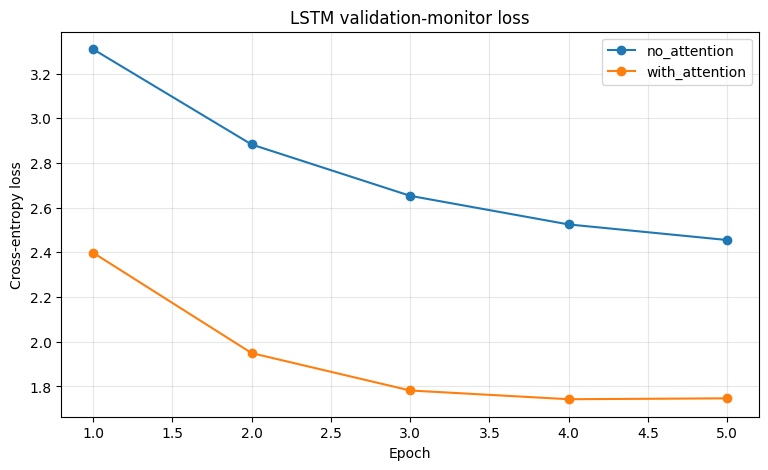

,model,epoch,train_loss,monitor_loss,training_seconds
0,no_attention,1,3.985112,3.309126,18.166770
1,no_attention,2,2.904845,2.882739,10.732846
2,no_attention,3,2.436297,2.653045,10.985327
3,no_attention,4,2.104008,2.524919,11.514423
4,no_attention,5,1.842054,2.455154,11.446562
5,with_attention,1,3.339285,2.398308,21.052851
6,with_attention,2,1.827153,1.949098,15.879760
7,with_attention,3,1.315333,1.781767,16.157065
8,with_attention,4,1.018059,1.742682,16.272689
9,with_attention,5,0.810140,1.746690,15.745761


In [14]:
history_df = pd.DataFrame(plain_history + attention_history)
fig, ax = plt.subplots(figsize=(9, 5))
for label, group in history_df.groupby('model'):
    ax.plot(group['epoch'], group['monitor_loss'], marker='o', label=label)
ax.set_title('LSTM validation-monitor loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-entropy loss')
ax.legend()
ax.grid(alpha=0.3)
plt.show()
display(history_df)

In [15]:
@torch.inference_mode()
def translate_lstm(model, sentences, batch_size=32):
    model.eval()
    predictions = []
    for start in range(0, len(sentences), batch_size):
        texts = sentences[start:start + batch_size]
        src_tokens = [torch.tensor(encode_english(s), dtype=torch.long) for s in texts]
        source = pad_sequence(src_tokens, batch_first=True,
                              padding_value=PAD_ID).to(DEVICE)
        encoder_outputs, states, source_is_pad = model.encode(source)
        previous = torch.full((len(texts), 1), BOS_ID, dtype=torch.long, device=DEVICE)
        finished = torch.zeros(len(texts), dtype=torch.bool, device=DEVICE)
        sequences = [[] for _ in texts]

        for _ in range(MAX_LEN - 1):
            logits, states = model.decode(
                previous, states, encoder_outputs, source_is_pad
            )
            next_tokens = logits[:, -1, :].argmax(dim=-1)
            next_tokens = torch.where(
                finished, torch.full_like(next_tokens, EOS_ID), next_tokens
            )
            next_list = next_tokens.tolist()
            was_finished = finished.tolist()
            for i, token_id in enumerate(next_list):
                if not was_finished[i] and token_id != EOS_ID:
                    sequences[i].append(token_id)
            finished = finished | next_tokens.eq(EOS_ID)
            previous = next_tokens.unsqueeze(1)
            if bool(finished.all()):
                break

        predictions.extend(fr_sp.decode(ids) for ids in sequences)
    return predictions

samples = ['I am happy.', 'Where is the train station?', 'She reads a book.']
print('Sample translations (illustrative; not test scores):')
for source, a, b in zip(samples, translate_lstm(plain_lstm, samples),
                       translate_lstm(attention_lstm, samples)):
    print('English:', source)
    print('LSTM:', a)
    print('LSTM + attention:', b)
    print('---')

Sample translations (illustrative; not test scores):
English: I am happy.
LSTM: Je suis heureux.
LSTM + attention: Je suis heureux.
---
English: Where is the train station?
LSTM: Où est la gare ?
LSTM + attention: Où est la gare ?
---
English: She reads a book.
LSTM: Elle a acheté une table.
LSTM + attention: Elle lit un livre.
---


In [16]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = 'Helsinki-NLP/opus-mt-en-fr'
marian_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
marian_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE)
marian_model.eval()

@torch.inference_mode()
def translate_marian(sentences, batch_size=8):
    predictions = []
    for start in range(0, len(sentences), batch_size):
        batch = sentences[start:start + batch_size]
        model_input = marian_tokenizer(
            batch, padding=True, truncation=True, max_length=64,
            return_tensors='pt'
        ).to(DEVICE)
        output_ids = marian_model.generate(
            **model_input, num_beams=1, do_sample=False, max_new_tokens=64
        )
        predictions.extend(marian_tokenizer.batch_decode(
            output_ids, skip_special_tokens=True
        ))
        if (start // batch_size + 1) % 50 == 0:
            print('MarianMT generated:', min(start + batch_size, len(sentences)),
                  '/', len(sentences))
    return predictions

print('MarianMT loaded:', MODEL_NAME)

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  301MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

MarianMT loaded: Helsinki-NLP/opus-mt-en-fr


In [17]:
test_english = test_df['en'].tolist()
test_references = test_df['fr'].tolist()
assert len(test_english) == len(test_references) == TEST_SIZE

def timed_predictions(fn, sentences, label):
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()
    preds = fn(sentences)
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    assert len(preds) == len(sentences)
    print(label, ':', len(preds), 'translations in', round(elapsed, 2), 's')
    return preds, elapsed

plain_preds, plain_seconds = timed_predictions(
    lambda x: translate_lstm(plain_lstm, x), test_english, 'LSTM without attention'
)
attention_preds, attention_seconds = timed_predictions(
    lambda x: translate_lstm(attention_lstm, x), test_english, 'LSTM with attention'
)
marian_preds, marian_seconds = timed_predictions(
    translate_marian, test_english, 'MarianMT pretrained Transformer'
)
print('All three models have translated the identical 2,000 test inputs.')

LSTM without attention : 2000 translations in 1.43 s


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


LSTM with attention : 2000 translations in 2.91 s


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

MarianMT generated: 400 / 2000


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

... (3 outputs left out)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

MarianMT generated: 1600 / 2000


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

MarianMT generated: 2000 / 2000
MarianMT pretrained Transformer : 2000 translations in 35.07 s
All three models have translated the identical 2,000 test inputs.


In [18]:
model_outputs = {
    'LSTM without attention': (plain_preds, plain_seconds),
    'LSTM with attention': (attention_preds, attention_seconds),
    'MarianMT pretrained Transformer': (marian_preds, marian_seconds),
}

metrics_rows = []
for model_name, (predictions, elapsed) in model_outputs.items():
    bleu = sacrebleu.corpus_bleu(predictions, [test_references]).score
    chrf = sacrebleu.corpus_chrf(predictions, [test_references]).score
    metrics_rows.append({
        'Model': model_name, 'BLEU': round(bleu, 2),
        'chrF': round(chrf, 2), 'Test sentences': TEST_SIZE,
        'Inference time (s)': round(elapsed, 2),
    })

metrics_df = pd.DataFrame(metrics_rows)
print('FINAL HELD-OUT TEST RESULTS — same 2,000 sentences')
display(metrics_df)

plain_bleu = metrics_df.loc[metrics_df['Model'] == 'LSTM without attention', 'BLEU'].iloc[0]
attention_bleu = metrics_df.loc[metrics_df['Model'] == 'LSTM with attention', 'BLEU'].iloc[0]
print('Attention vs no-attention BLEU difference:', round(attention_bleu - plain_bleu, 2),
      'points (descriptive, not a significance test)')

FINAL HELD-OUT TEST RESULTS — same 2,000 sentences


,Model,BLEU,chrF,Test sentences,Inference time (s)
0,LSTM without attention,10.46,28.24,2000,1.43
1,LSTM with attention,31.04,51.10,2000,2.91
2,MarianMT pretrained Transformer,53.74,68.69,2000,35.07


Attention vs no-attention BLEU difference: 20.58 points (descriptive, not a significance test)


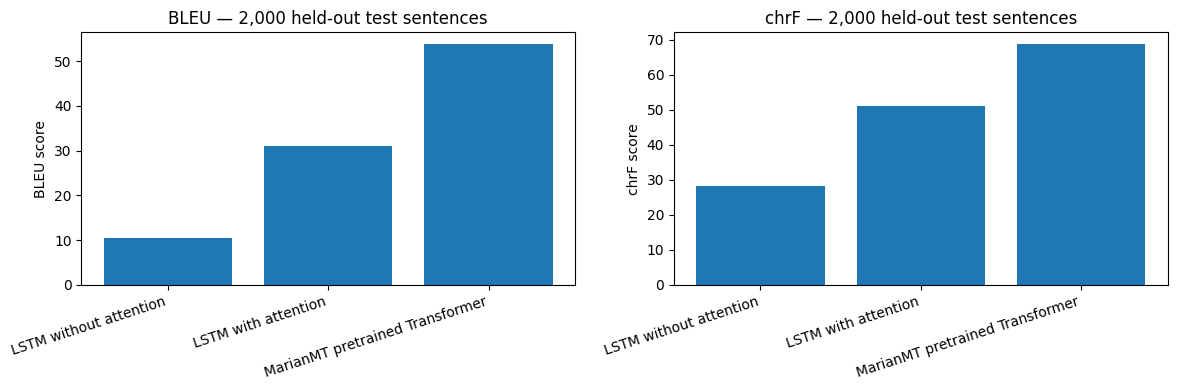

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['BLEU', 'chrF']):
    ax.bar(metrics_df['Model'], metrics_df[metric])
    ax.set_title(metric + ' — 2,000 held-out test sentences')
    ax.set_ylabel(metric + ' score')
    ax.tick_params(axis='x', labelrotation=18)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
plt.tight_layout()
plt.show()

In [20]:
comparison_df = test_df[['en', 'fr']].copy()
comparison_df['LSTM without attention'] = plain_preds
comparison_df['LSTM with attention'] = attention_preds
comparison_df['MarianMT Transformer'] = marian_preds
comparison_df['LSTM sentence chrF'] = [
    round(sacrebleu.sentence_chrf(p, [r]).score, 2)
    for p, r in zip(plain_preds, test_references)
]
comparison_df['Attention sentence chrF'] = [
    round(sacrebleu.sentence_chrf(p, [r]).score, 2)
    for p, r in zip(attention_preds, test_references)
]
print('10 random comparisons:')
display(comparison_df.sample(n=10, random_state=SEED))
print('10 low-scoring no-attention LSTM examples:')
display(comparison_df.nsmallest(10, 'LSTM sentence chrF'))

10 random comparisons:


,en,fr,LSTM without attention,LSTM with attention,MarianMT Transformer,LSTM sentence chrF,Attention sentence chrF
1860,Tom is now a businessman.,Tom est maintenant homme d'affaire.,Tom est un peu fatigué.,Tom est maintenant un homme.,Tom est maintenant un homme d'affaires.,17.72,59.63
353,I can't believe we finally made it.,Je n'arrive pas à croire que nous y avons fina...,Je n'arrive pas à croire que nous soyons fait ...,Je n'arrive pas à croire que nous le reconnmes.,Je n'arrive pas à croire qu'on soit enfin arri...,60.63,58.57
1333,"More than 3,000 people were at the concert.",Plus de 3 000 personnes étaient au concert.,Plus de gens vivent dans le monde entier de la...,Plus de 3000 personnes étaient au concert.,Plus de 3000 personnes étaient au concert.,22.16,100.00
905,I found out how to solve the problem.,Je trouvai comment résoudre le problème.,J'ai trouvé le problème difficile à faire.,Je suis sorti comment résoudre le problème.,J'ai trouvé comment résoudre le problème.,36.80,77.71
1289,She advised him to take a rest.,Elle lui conseilla de prendre du repos.,Elle lui a conseillé de faire confiance.,Elle lui a conseillé de prendre un repos.,Elle lui a conseillé de se reposer.,37.61,65.11
1273,Here is the fish my mother baked.,Voici le poisson que ma mère a cuit.,Voici la porte de mon père.,Voici le poisson de ma mère.,Voici le poisson que ma mère a cuit.,25.18,63.22
938,I couldn't live like that.,Je ne pourrais pas vivre ainsi.,Je n'aurais pas pu faire ça.,Je n'ai pas pu vivre ça.,Je ne pouvais pas vivre comme ça.,29.89,24.62
1731,I've finally gotten over my cold.,J'ai finalement réussi à vaincre mon rhume.,J'ai toujours aimé mon parapluie.,J'ai finalement partout mon rhume.,Je me suis enfin remis de mon rhume.,15.76,55.40
65,The boy is full of promise.,Ce garçon porte plein de promesses.,Le garçon est en train de se marier en anglais.,Le garçon est pleine de promesse.,Le garçon est plein de promesses.,30.20,55.35
1323,Let's ask the boy who lives next door.,Posons la question au garçon qui habite à côté.,Voyons voir ce que l'homme s'est passé la nuit.,Demandons le garçon qui vit prochain.,Demande au garçon qui vit à côté.,16.41,29.11


10 low-scoring no-attention LSTM examples:


,en,fr,LSTM without attention,LSTM with attention,MarianMT Transformer,LSTM sentence chrF,Attention sentence chrF
45,Get on your horse.,En selle.,Va chercher votre verre !,Épeez-toi sur ton cheval.,Monte sur ton cheval.,3.14,9.26
1578,It came as a surprise.,C'est arrivé par surprise.,Ça a un peu mal.,C'est comme une surprise.,C'est venu comme une surprise.,4.81,43.22
1861,Will you be much longer?,Ça va te prendre encore longtemps ?,M'étiez-vous bien ?,Cela vous dérangerait-t-il longtemps ?,Tu vas rester longtemps ?,5.66,34.25
1588,They keep calling.,Elles ne cessent d'appeler.,Ils ont gagné.,Ils continuent des fûtes.,Ils n'arrêtent pas d'appeler.,6.21,15.22
1779,It goes both ways.,Ça fonctionne dans les deux sens.,Ça va à l'école.,Ça va toutes les deux.,Ça va dans les deux sens.,6.72,28.16
1137,Let's just listen.,"Écoutons, simplement !",Essayons.,Nettons simplement.,Écoute.,6.79,52.28
251,The building collapsed in the earthquake.,Le bâtiment s'effondra lors du tremblement de ...,Le bébé a été annulé à la plage.,Le bâtiment s'est mis en collouga.,Le bâtiment s'est effondré dans le tremblement...,6.96,32.18
257,What's the rush?,Pourquoi cette précipitation ?,Quel est le nom de votre nom ?,Quelle est la bière ?,Pourquoi tu te presses ?,7.00,5.33
92,It belongs to me now.,Il m'appartient désormais.,Ça me rend heureux de venir.,Ça me renda maintenant.,Il m'appartient maintenant.,7.03,13.13
1417,He usually goes to work at 8 a.m.,"Habituellement, il part au travail à 8 heures ...",Il va à Paris à la gare.,Il va habituellement au travail au coin.,Il va habituellement travailler à 8 heures du ...,7.04,47.39


In [21]:
metrics_csv = RESULTS_DIR / 'three_model_test_metrics.csv'
predictions_csv = RESULTS_DIR / 'three_model_test_predictions.csv'
history_csv = RESULTS_DIR / 'lstm_training_history.csv'
metadata_json = RESULTS_DIR / 'three_model_test_metadata.json'

metrics_df.to_csv(metrics_csv, index=False)
comparison_df.to_csv(predictions_csv, index=False)
history_df.to_csv(history_csv, index=False)

metadata = {
    'dataset_url': DATA_URL,
    'original_pairs': raw_count,
    'cleaned_pairs': len(pairs),
    'train_partition': len(train_pairs),
    'validation_partition': len(val_pairs),
    'test_partition': len(test_pairs),
    'training_pairs_per_lstm': len(train_df),
    'monitor_pairs': len(monitor_df),
    'test_sentences': TEST_SIZE,
    'test_sample_random_state': SEED,
    'transformer_model': MODEL_NAME,
    'decoding': 'greedy for all three models',
    'config': CONFIG,
    'remarks': 'LSTMs trained from scratch; MarianMT pretrained. Test scores are not an architecture-only comparison.',
}
metadata_json.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

# Back up result files to Drive as well as saving the trained models.
for path in [metrics_csv, predictions_csv, history_csv, metadata_json]:
    shutil.copy2(path, SAVE_DIR / path.name)

archive_base = Path('nmt_three_model_results')
shutil.make_archive(str(archive_base), 'zip', root_dir='.', base_dir='results')
shutil.copy2(str(archive_base) + '.zip', SAVE_DIR / (archive_base.name + '.zip'))

print('RESULTS READY')
print('Local results folder:', RESULTS_DIR.resolve())
print('Google Drive folder:', SAVE_DIR.resolve())
print('ZIP:', str(archive_base) + '.zip')
print('Model checkpoints:')
print('-', SAVE_DIR / 'lstm_no_attention_complete.pt')
print('-', SAVE_DIR / 'lstm_with_attention_complete.pt')

RESULTS READY
Local results folder: /content/results
Google Drive folder: /content/drive/MyDrive/NMT_Three_Model_Comparison
ZIP: nmt_three_model_results.zip
Model checkpoints:
- /content/drive/MyDrive/NMT_Three_Model_Comparison/lstm_no_attention_complete.pt
- /content/drive/MyDrive/NMT_Three_Model_Comparison/lstm_with_attention_complete.pt


In [22]:
try:
    from google.colab import files
    files.download('nmt_three_model_results.zip')
except ImportError:
    print('Outside Colab: download nmt_three_model_results.zip from your file browser.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>